# 03 · The Second Descent

**Claim:** add parameters past the interpolation threshold, into more parameters than data points, and test error comes **down again**, while training error stays at exactly zero. In 20-D random features it ends up **below** the classical sweet spot.

This is the showpiece: the full double-descent curve, drawn from scratch with nothing more exotic than least squares.

*Double Descent 101 · notebook 3 of 6 · previous: [02 · The interpolation peak](02_the_interpolation_peak.ipynb) · next: [04 · Benign overfitting](04_benign_overfitting.ipynb)*

In [1]:
import numpy as np
import pandas as pd

from src.config import get_settings
from src.evaluation import aggregate, example_fits, factory_for, run_capacity_experiment, summarize_curve, task_for
from src.evaluation.comparison import MODEL_LABELS
from src.reporting import publish_figure, save_json
from src.theory.decomposition import bias_variance
from src.visualisation import (
    BIAS_COLOR, INK, INK_2, MODEL_COLORS, SERIES, TRAIN_COLOR, VARIANCE_COLOR,
    annotate_point, capacity_axes, format_error, new_figure, plot_curve, plot_decomposition, plot_fit,
)

settings = get_settings()
SIGMA = settings.headline_noise
N = {"polynomial": settings.polynomial.n_train, "random_features": settings.random_features.n_train}
sweeps = {m: run_capacity_experiment(m, settings, noise_levels=[SIGMA]) for m in N}
test = {m: aggregate(df) for m, df in sweeps.items()}
train = {m: aggregate(df, value="train_mse") for m, df in sweeps.items()}
summ = {m: summarize_curve(test[m], N[m]) for m in N}
pd.DataFrame({m: s.to_dict() for m, s in summ.items()})

,polynomial,random_features
n_train,15,100
classical_min_params,5,32
classical_min_error,0.124077,0.416722
peak_params,15,100
peak_error,3210621083.103967,71.448123
second_min_params,90,2000
second_min_error,0.158958,0.242518
final_params,90,2000
final_error,0.158958,0.242518
beats_classical,False,True


## The whole curve

Same tracks, same min-norm fit, $\sigma = 0.3$. The polynomial now runs to degree 89 (six times more parameters than points) and the random features to 2,000 (twenty times more). The x-axis is logarithmic so both regimes get room.

{'png': '/workspaces/double_descent_101/outputs/figures/03_double_descent.png',
 'json': '/workspaces/double_descent_101/outputs/data/03_double_descent.json'}

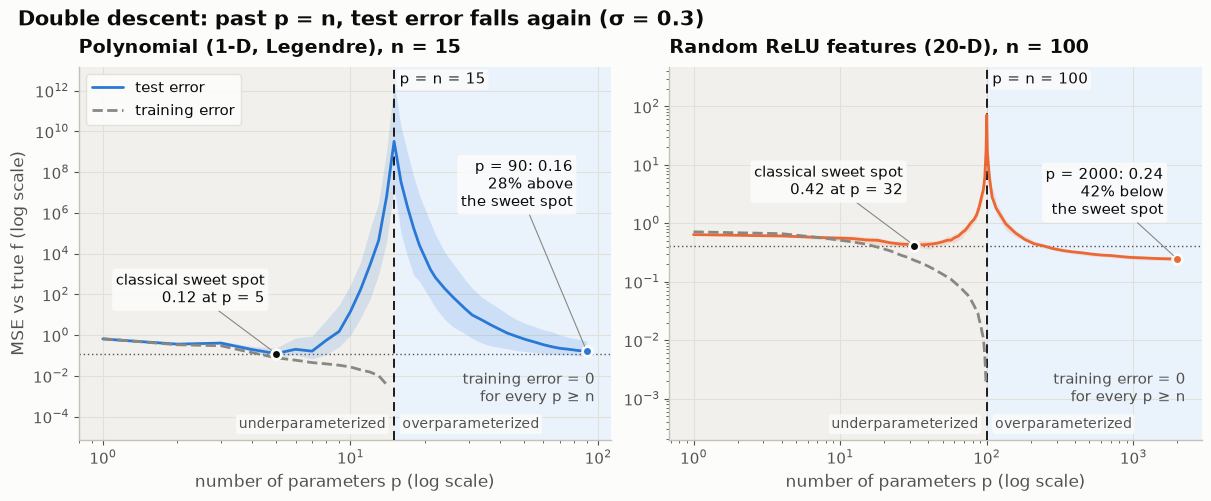

In [2]:
fig, axes = new_figure(ncols=2, width=12.0, height=4.9)
fig_data = {}
for ax, m in zip(axes, N):
    n, s, col = N[m], summ[m], MODEL_COLORS[m]
    plot_curve(ax, test[m], col, "test error")
    tr = train[m][train[m]["n_params"] < n]
    plot_curve(ax, tr, TRAIN_COLOR, "training error", band=False, ls="--")
    ax.axhline(s.classical_min_error, color=INK_2, lw=1.0, ls=(0, (1, 2)), zorder=2)
    capacity_axes(ax, n, xlabel="number of parameters p (log scale)", logx=True,
                  ylabel="MSE vs true f (log scale)" if m == "polynomial" else "")
    annotate_point(ax, s.classical_min_params, s.classical_min_error,
                   f"classical sweet spot\n{format_error(s.classical_min_error)} at p = {s.classical_min_params}", dx=-8, dy=46, ha="right")
    change = s.second_min_error / s.classical_min_error - 1
    verdict = f"{abs(change):.0%} {'below' if change < 0 else 'above'}\nthe sweet spot"
    annotate_point(ax, s.second_min_params, s.second_min_error,
                   f"p = {s.second_min_params}: {format_error(s.second_min_error)}\n{verdict}", dx=-10,
                   dy=120 if m == "polynomial" else 48, ha="right", color=col)
    ax.annotate("training error = 0\nfor every p ≥ n", xy=(0.97, 0.09), xycoords="axes fraction", ha="right",
                va="bottom", fontsize=10.5, color=INK_2)
    ax.set_title(f"{MODEL_LABELS[m]}, n = {n}")
    fig_data[m] = {
        "n_train": n, "n_params": test[m]["n_params"].tolist(),
        "test_median": test[m]["median"].tolist(), "test_q25": test[m]["q25"].tolist(), "test_q75": test[m]["q75"].tolist(),
        "train_median": train[m]["median"].tolist(), "summary": s.to_dict(),
    }
axes[0].legend(loc="upper left")
fig.suptitle(f"Double descent: past p = n, test error falls again (σ = {SIGMA})", x=0.01, ha="left")
publish_figure(
    fig, "03_double_descent", "Double descent",
    f"Median test error (vs the noiseless truth) and training error across the interpolation threshold, σ = {SIGMA}. "
    "Dotted line: the classical sweet spot. Training error is exactly zero (to machine precision) for every p ≥ n.",
    {"noise": SIGMA, **fig_data},
)

Reading the two panels against each other:

- **Polynomial (1-D):** after the peak of $\sim 3\times10^9$ at $p = 15$ the error falls by ten orders of magnitude, to about **0.16** at $p = 90$. That is far better than anything near the threshold, but still about 30% above the sweet spot (0.12 at $p = 5$).
- **Random features (20-D):** after the peak of about 71 at $p = 100$ the error keeps falling to about **0.24** at $p = 2000$: roughly **40% below** the classical sweet spot (0.42 at $p = 32$). The best model memorises every noisy training point and has twenty times more parameters than data.

The second descent is general. Whether it *beats* the sweet spot depends on the setting, and high dimension is where it does (more on why in notebook 04).

## The curves themselves

One polynomial training draw at the three landmarks: the sweet spot, the threshold, and far past it.

{'png': '/workspaces/double_descent_101/outputs/figures/03_fits_across_threshold.png',
 'json': '/workspaces/double_descent_101/outputs/data/03_fits_across_threshold.json'}

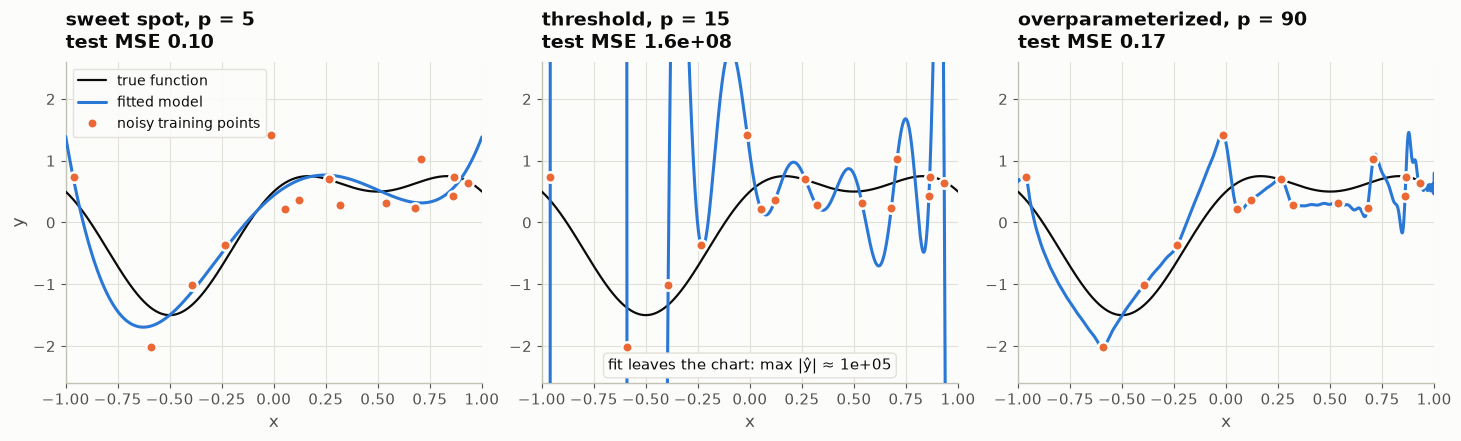

In [3]:
n = N["polynomial"]
sizes = [summ["polynomial"].classical_min_params, n, summ["polynomial"].final_params]
names = ["sweet spot", "threshold", "overparameterized"]
ex = example_fits(settings, sizes, noise=SIGMA)
fig, axes = new_figure(ncols=3, width=14.5, height=4.3)
for ax, p, name in zip(axes, sizes, names):
    plot_fit(ax, ex.x_grid, ex.f_grid, ex.x_train, ex.y_train, ex.predictions[p], label="fitted model")
    ax.set_title(f"{name}, p = {p}\ntest MSE {format_error(ex.test_mse[p])}")
for ax in axes[1:]:
    ax.set_ylabel("")
axes[0].legend(loc="upper left", fontsize=10)
publish_figure(
    fig, "03_fits_across_threshold", "From smooth, to contorted, to smooth again",
    f"One draw of {n} noisy points (σ = {SIGMA}) fitted with {sizes[0]}, {sizes[1]} and {sizes[2]} Legendre parameters "
    "(min-norm). The last two both pass through every training point.",
    {"noise": SIGMA, "x_train": ex.x_train, "y_train": ex.y_train, "x_grid": ex.x_grid[::10], "f_grid": ex.f_grid[::10],
     "fits": {str(p): {"prediction": ex.predictions[p][::10], "train_mse": ex.train_mse[p], "test_mse": ex.test_mse[p]} for p in sizes}},
)

The middle and right panels both have zero training error. They differ only in **which** interpolating curve the solver picked. At $p = n$ there is exactly one, and it is grotesque. At $p = 6n$ there are infinitely many, and minimum-norm least squares picks the one with the smallest coefficients. Here that means following the overall trend and absorbing each noisy point with a small local kink. It is not perfectly smooth, but it is nothing like the threshold fit.

## Where the second descent comes from: variance

The same bias-variance decomposition as notebook 01, now across the threshold (random-feature track, averages over independent training draws with fresh features).

,n_train,noise,bias2,variance,expected_mse,noise_var
n_params,,,,,,
32,100,0.3,0.141,0.288,0.429,0.09
100,100,0.3,10.436,5370.191,5380.628,0.09
2000,100,0.3,0.101,0.137,0.239,0.09


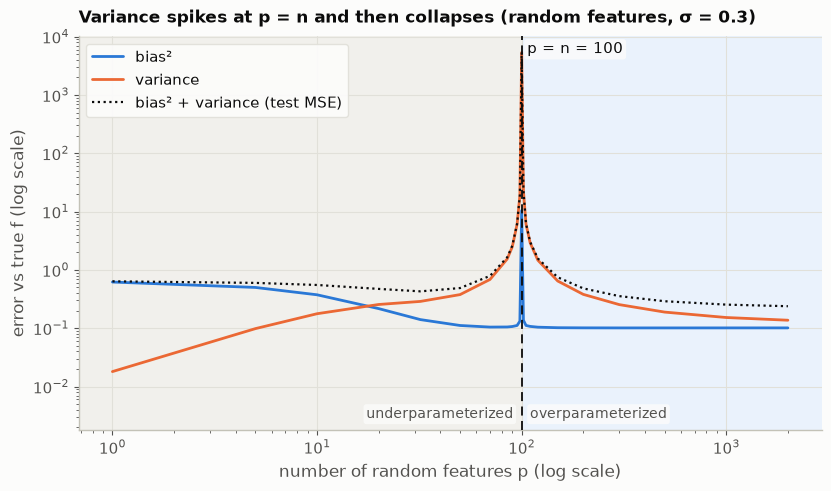

In [4]:
m = "random_features"
n = N[m]
dec_grid = [1, 5, 10, 20, 32, 50, 70, 85, 90, 95, 98, 100, 102, 105, 110, 120, 150, 200, 300, 500, 1000, 2000]
dec = bias_variance(factory_for(m, settings), task_for(m, settings), n_train=n, noise=SIGMA,
                    n_params_grid=dec_grid, n_draws=settings.random_features.decomposition_draws, seed=settings.seed)
assert np.allclose(dec["bias2"] + dec["variance"], dec["expected_mse"])

fig, (ax,) = new_figure(width=8.2, height=4.8)
plot_decomposition(ax, dec, n)
capacity_axes(ax, n, xlabel="number of random features p (log scale)", ylabel="error vs true f (log scale)", logx=True)
ax.set_title(f"Variance spikes at p = n and then collapses (random features, σ = {SIGMA})", fontsize=12.5)
ax.legend(loc="upper left")
publish_figure(
    fig, "03_bias_variance_across_threshold", "Variance spikes, then collapses",
    f"Bias-variance decomposition over {settings.random_features.decomposition_draws} independent training draws "
    f"(fresh inputs, noise and features), random-feature track, n = {n}, σ = {SIGMA}. These are means, so the "
    "threshold value is dominated by the rare near-singular draw.",
    {"noise": SIGMA, "n_train": n, "n_draws": settings.random_features.decomposition_draws, "decomposition": dec},
)
dec.set_index("n_params").loc[[32, 100, 2000]].round(3)

**Bias** falls in the classical regime and then stays flat at about 0.10 on both sides of the threshold. The exception is a blip at $p = n$ itself, where a few near-singular draws drag even the *average* prediction off. Past $p = n$ the model can already represent everything it is going to. **Variance** does all the work: it spikes at $p = n$ (the fit is hostage to the exact noise draw) and then falls steadily as more features give the min-norm solution more room to spread the noise thinly. The classical decomposition is not wrong. Variance is just not monotone in capacity.

## Which interpolant is the whole story

"Minimum norm" depends on the basis the norm is measured in. The polynomial track scales the Legendre polynomial $P_k$ by $1/(1+k)$ (`decay = 1` in `config/settings.yaml`), so high-order wiggles are "expensive" and the min-norm interpolant prefers smooth explanations. Turn that off (`decay = 0`, every Legendre polynomial equally cheap) and the fits below the threshold do not change at all. Least squares there has a unique answer. Past the threshold the choice of interpolant changes completely.

{'png': '/workspaces/double_descent_101/outputs/figures/03_which_interpolant.png',
 'json': '/workspaces/double_descent_101/outputs/data/03_which_interpolant.json'}

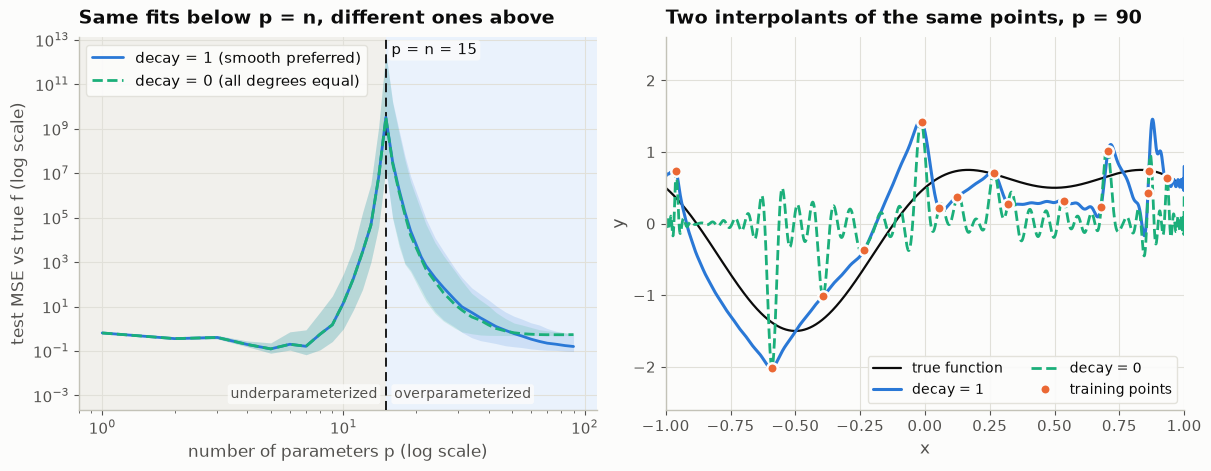

In [5]:
flat = settings.model_copy(update={"polynomial": settings.polynomial.model_copy(update={"decay": 0.0})})
flat_test = aggregate(run_capacity_experiment("polynomial", flat, noise_levels=[SIGMA]))
n = N["polynomial"]
p_far = summ["polynomial"].final_params
ex_flat = example_fits(flat, [p_far], noise=SIGMA)

fig, axes = new_figure(ncols=2, width=12.0, height=4.6)
plot_curve(axes[0], test["polynomial"], SERIES[0], "decay = 1 (smooth preferred)")
plot_curve(axes[0], flat_test, SERIES[2], "decay = 0 (all degrees equal)", ls="--")
capacity_axes(axes[0], n, xlabel="number of parameters p (log scale)", logx=True)
axes[0].legend(loc="upper left")
axes[0].set_title("Same fits below p = n, different ones above")
axes[1].plot(ex.x_grid, ex.f_grid, color=INK, lw=1.6, label="true function")
axes[1].plot(ex.x_grid, ex.predictions[p_far], color=SERIES[0], lw=2.2, label="decay = 1")
axes[1].plot(ex.x_grid, ex_flat.predictions[p_far], color=SERIES[2], lw=2.0, ls="--", label="decay = 0")
axes[1].plot(ex.x_train, ex.y_train, "o", ms=7.5, color=SERIES[1], mec="#fcfcfb", mew=1.8, label="training points", zorder=5)
axes[1].set_ylim(-2.6, 2.6)
axes[1].set_xlim(-1, 1)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].legend(loc="lower right", fontsize=10, ncols=2)
axes[1].set_title(f"Two interpolants of the same points, p = {p_far}")
publish_figure(
    fig, "03_which_interpolant", "The basis decides which interpolant",
    "Left: median test error of min-norm polynomial fits with Legendre features scaled by 1/(1+k) (decay = 1) "
    "or unscaled (decay = 0). Right: both interpolants of one draw at p = 6n. Both pass through every point; "
    "the unscaled one collapses towards zero between them.",
    {"noise": SIGMA, "n_params": test["polynomial"]["n_params"].tolist(),
     "decay_1_median": test["polynomial"]["median"].tolist(), "decay_0_median": flat_test["median"].tolist(),
     "x_grid": ex.x_grid[::10], "fit_decay_1": ex.predictions[p_far][::10], "fit_decay_0": ex_flat.predictions[p_far][::10],
     "test_mse": {"decay_1": ex.test_mse[p_far], "decay_0": ex_flat.test_mse[p_far]}},
)

With every degree equally cheap, the min-norm interpolant spends its budget on high-order spikes at the training points and decays to zero in between. Its error plateaus near the "always predict zero" baseline. Same data, same zero training error, completely different generalisation. Interpolating is not the problem. *Which* interpolant you get is the whole story, and least squares through the pseudo-inverse quietly picks a good one when the features make smooth functions cheap.

## What you just saw

- **The full curve:** classical U, a spike at $p = n$, then a second descent with training error pinned at zero.
- **It can beat the sweet spot.** In 20-D random features the interpolating model with 2,000 parameters has about 40% lower test error than the best classical model. In 1-D polynomials the second descent falls ten orders of magnitude but levels off just above the sweet spot.
- **Mechanism:** bias is flat past the threshold; variance spikes and then collapses.
- **Which interpolant matters:** the min-norm solution is only as good as the norm. Scale features so smooth functions are cheap and the overparameterized fit is calm.

Next, notebook 04 takes the most uncomfortable part of this seriously: zero training error on noisy labels, and still good predictions.

In [6]:
save_json(
    {
        "notebook": "03_the_second_descent",
        "claim": "Past the interpolation threshold test error descends again with zero training error, and in 20-D random features it beats the classical sweet spot.",
        "settings": {"headline_noise": SIGMA, "n_train": N, "polynomial_decay": settings.polynomial.decay,
                     "decomposition_draws": settings.random_features.decomposition_draws, "seed": settings.seed},
        "results": {
            "curves": {m: s.to_dict() for m, s in summ.items()},
            "rf_improvement_over_sweet_spot": 1 - summ["random_features"].second_min_error / summ["random_features"].classical_min_error,
            "poly_gap_to_sweet_spot": summ["polynomial"].second_min_error / summ["polynomial"].classical_min_error - 1,
            "decomposition_at": dec.set_index("n_params").loc[[32, 100, 2000], ["bias2", "variance", "expected_mse"]].to_dict(orient="index"),
            "decay_0_final_median": float(flat_test["median"].iloc[-1]),
            "decay_1_final_median": float(test["polynomial"]["median"].iloc[-1]),
        },
        "figures": ["03_double_descent", "03_fits_across_threshold", "03_bias_variance_across_threshold", "03_which_interpolant"],
        "takeaways": [
            "Past p = n test error descends again while training error stays at zero.",
            "In 20-D random features the second descent beats the classical sweet spot; in 1-D polynomials it levels off just above it.",
            "Bias is flat past the threshold; variance spikes at p = n and then collapses.",
            "Which interpolant the solver picks (set by the feature scaling) decides how well an interpolating model generalises.",
        ],
        "next": "04_benign_overfitting",
    },
    "03_summary",
)

PosixPath('/workspaces/double_descent_101/outputs/data/03_summary.json')